# SNN Motion Detection — Results Comparison Notebook

### Group-SNN1
### Course:Neural networks and learning machines D7046E
Luleå University of Technology

---

#  Content

##  1.  Project Result Overview
##  2. LIF (Simple) Model Results
##  3.  Reichardt Model Results
##  4.  Brian2 Results
##  5.  Comparison Table
##  6.  Conclusion

---
## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import os

# ── Path to  figures folder ───────────────────────────────
IMG_PATH = '/content/drive/.shortcut-targets-by-id/1xSAWP0ipMAapy474kT08XY-56-MuIKDe/snn1_notebooks/results/part1_snnTorch/figures/'

# ── LIF (Simple) model images ─────────────────────────────────
LIF_ALL_CURVES  = IMG_PATH + 'all_sources_comparison.png'
LIF_CM_LIN_CIRC = IMG_PATH + 'confusion_linear_circular.png'
LIF_CM_DVS128   = IMG_PATH + 'confusion_dvs128.png'
LIF_CM_ALL      = IMG_PATH + 'confusion_matrices_comparison.png'
LIF_CM_SIMPLE   = IMG_PATH + 'confusion_simple.png'

# ── Reichardt model images ────────────────────────────────────
REICH_ALL_CURVES = IMG_PATH + 'simple_vs_reichardt_all.png'
REICH_ACC_BAR    = IMG_PATH + 'accuracy_comparison_bar.png'
REICH_CM         = IMG_PATH + 'confusion_reichardt.png'


# ── Brian2 model images ───────────────────────────────────────
B2_PATH = '/content/drive/.shortcut-targets-by-id/1xSAWP0ipMAapy474kT08XY-56-MuIKDe/snn1_notebooks/results/part2_Brian2/figures/'

B2_ACC     = B2_PATH + 'accuracy_per_sample.bmp'
B2_LOSS    = B2_PATH + 'loss_per_epoch.bmp'
B2_CM_LIN  = B2_PATH + 'confusion_matrix_linear.png'
B2_CM_CIRC = B2_PATH + 'confusion_matrix_circular.png'

# ── Helper functions ──────────────────────────────────────────
def show_image(ax, path, title, color):
    img = mpimg.imread(path)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(title, fontsize=12, fontweight='bold', color=color, pad=10)

def show_placeholder(ax, title, message):
    ax.set_facecolor('#FFF8F0')
    ax.text(0.5, 0.60,'Pending',
            transform=ax.transAxes, ha='center', va='center',
            fontsize=14, color='#DD8452', fontweight='bold')
    ax.text(0.5, 0.38, message,
            transform=ax.transAxes, ha='center', va='center',
            fontsize=10, color='gray', style='italic')
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor('#DD8452'); spine.set_linewidth(2)
    ax.set_title(title, fontsize=12, fontweight='bold', color='#DD8452', pad=10)

C_LIF       = '#4C72B0'   # blue
C_REICHARDT = '#C44E52'   # red
C_BRIAN2    = '#DD8452'   # orange

print('Setup complete')
print(f'Images folder: {IMG_PATH}')

Setup complete
Images folder: /content/drive/.shortcut-targets-by-id/1xSAWP0ipMAapy474kT08XY-56-MuIKDe/snn1_notebooks/results/part1_snnTorch/figures/


---
# Section 1 — Project Result Overview

This section gives a quick overview of all results across all models and datasets.

We tested **3 models** on **3 datasets**:

| Model | Type | Learning Rule | Datasets |
|---|---|---|---|
| **LIF (Simple)** | SNNTorch | Supervised — BPTT | Linear, Circular, DVS128 |
| **Reichardt** | SNNTorch | Supervised — BPTT | Linear, Circular, DVS128 |
| **Brian2** | Brian2 | Semisupervised — STDP | Linear, Circular |

| Dataset | Classes | Description |
|---|---|---|
| **LINEAR** | 2 | Left / Right motion |
| **CIRCULAR** | 2 | Clockwise / Counter-clockwise |
| **DVS128** | 11 | Real neuromorphic camera gestures |

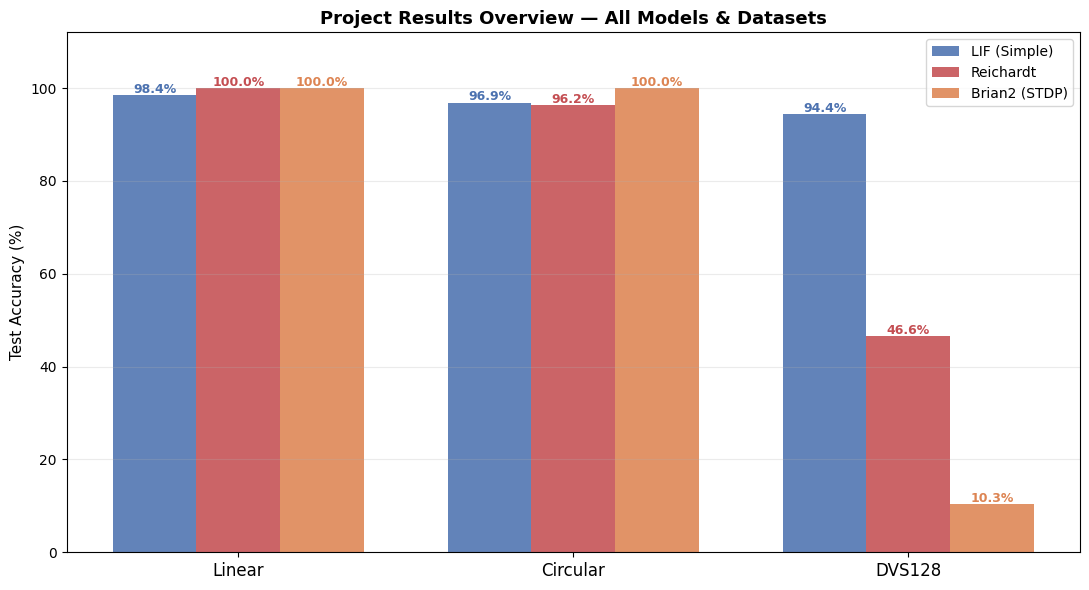

Section 1 overview saved


In [3]:
import numpy as np
# Overview bar chart — all models side by side
datasets = ['Linear', 'Circular', 'DVS128']

# ── Known results ─────────────────────────────────────────────
lif_accs       = [98.44, 96.88, 94.38]
reichardt_accs = [100.00, 96.25, 46.56]
brian2_accs    = [100.00, 100.00, 10.3]   # ← update later
# ─────────────────────────────────────────────────────────────

x = np.arange(len(datasets))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

# LIF bars
b1 = ax.bar(x - width, lif_accs, width, color=C_LIF, alpha=0.88, label='LIF (Simple)')
for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9, fontweight='bold', color=C_LIF)

# Reichardt bars
b2 = ax.bar(x, reichardt_accs, width, color=C_REICHARDT, alpha=0.88, label='Reichardt')
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9, fontweight='bold', color=C_REICHARDT)

# Brian2 bars
if any(v is not None for v in brian2_accs):
    vals = [v if v is not None else 0 for v in brian2_accs]
    b3 = ax.bar(x + width, vals, width, color=C_BRIAN2, alpha=0.88, label='Brian2 (STDP)')
    for bar in b3:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{bar.get_height():.1f}%', ha='center', fontsize=9, fontweight='bold', color=C_BRIAN2)
else:
    for i in range(len(datasets)):
        ax.bar(x[i] + width, 0, width, color=C_BRIAN2, alpha=0.25,
               label='Brian2 — pending' if i == 0 else '')
        ax.text(x[i] + width, 2, 'waiting', ha='center', fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(datasets, fontsize=12)
ax.set_ylabel('Test Accuracy (%)', fontsize=11)
ax.set_ylim(0, 112)
ax.set_title('Project Results Overview — All Models & Datasets',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION1_overview.png', bbox_inches='tight', dpi=120)
plt.show()
print('Section 1 overview saved')

---
# Section 2 — LIF Model Results

The **LIF (Leaky Integrate-and-Fire)** model is the Simple SNNTorch model.

- **Architecture:** Input(16384) → Hidden(32 × 2 layers) → Output
- **Learning:** Supervised — Backpropagation Through Time with surrogate gradients
- **Training:** Up to 50 epochs with early stopping (patience = 10)

| Dataset | Epochs | Test Accuracy |
|---|---|---|
| LINEAR | 50 | **98.44%** |
| CIRCULAR | 31 | **96.88%** |
| DVS128 | 50 | **94.38%** |

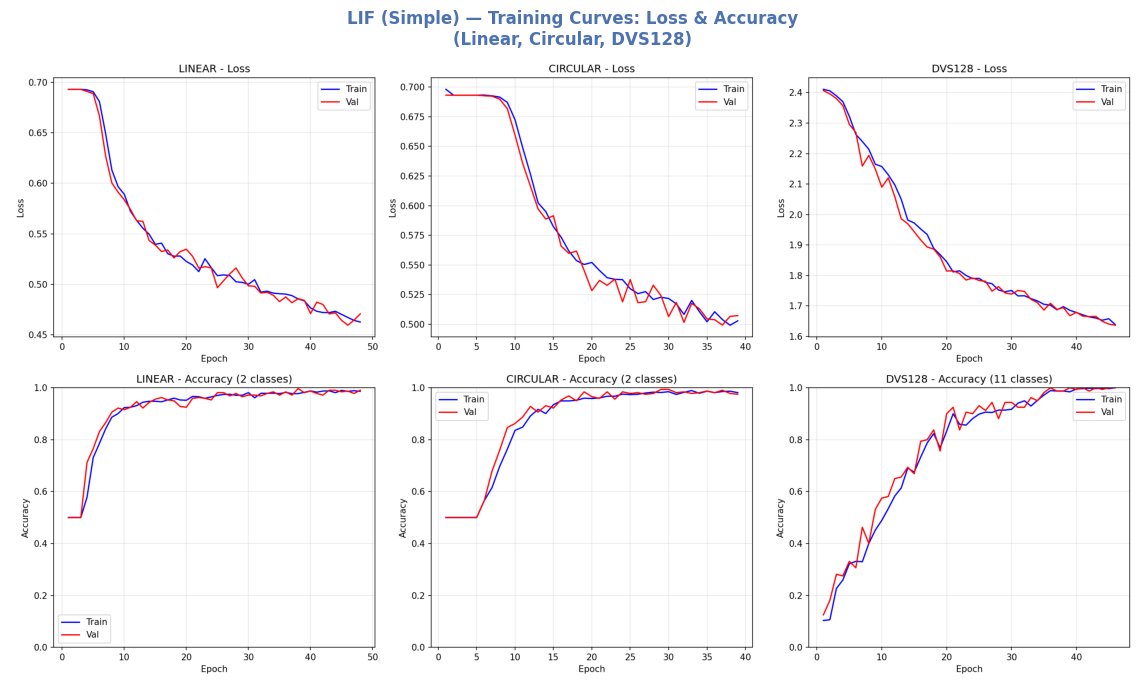

LIF training curves saved


In [4]:
# LIF — Training Curves
fig, ax = plt.subplots(figsize=(14, 7))
show_image(ax, LIF_ALL_CURVES,
           'LIF (Simple) — Training Curves: Loss & Accuracy\n(Linear, Circular, DVS128)',
           C_LIF)
plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION2_lif_curves.png', bbox_inches='tight', dpi=120)
plt.show()
print('LIF training curves saved')

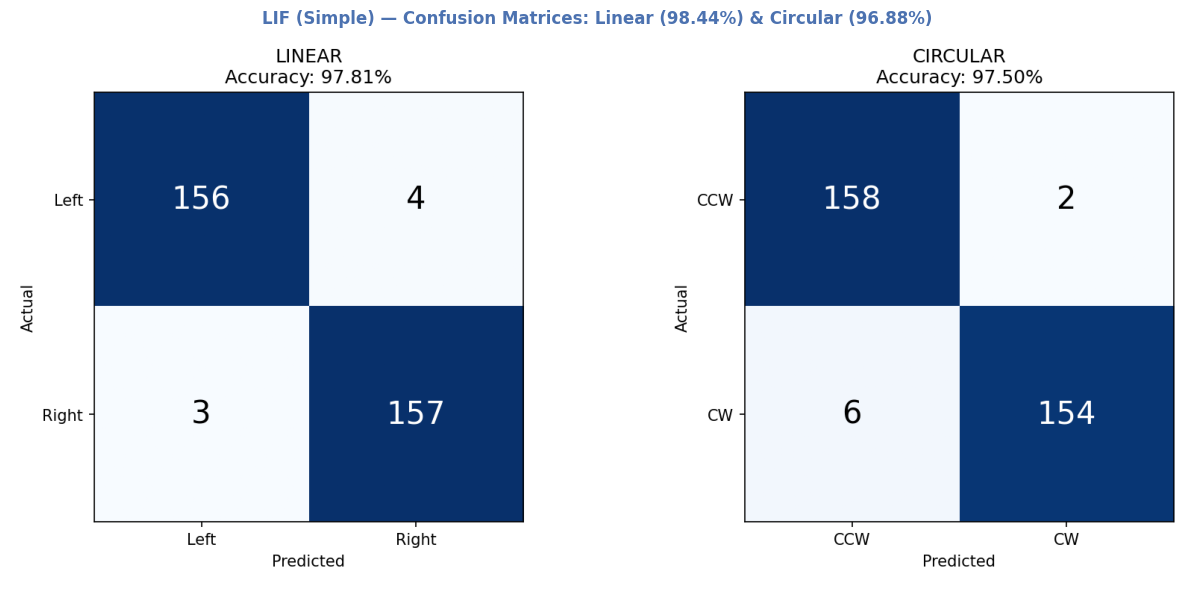

LIF Linear & Circular confusion matrices saved


In [5]:
# LIF — Confusion Matrices: Linear & Circular
fig, ax = plt.subplots(figsize=(14, 6))
show_image(ax, LIF_CM_LIN_CIRC,
           'LIF (Simple) — Confusion Matrices: Linear (98.44%) & Circular (96.88%)',
           C_LIF)
plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION2_lif_cm_lin_circ.png', bbox_inches='tight', dpi=120)
plt.show()
print('LIF Linear & Circular confusion matrices saved')

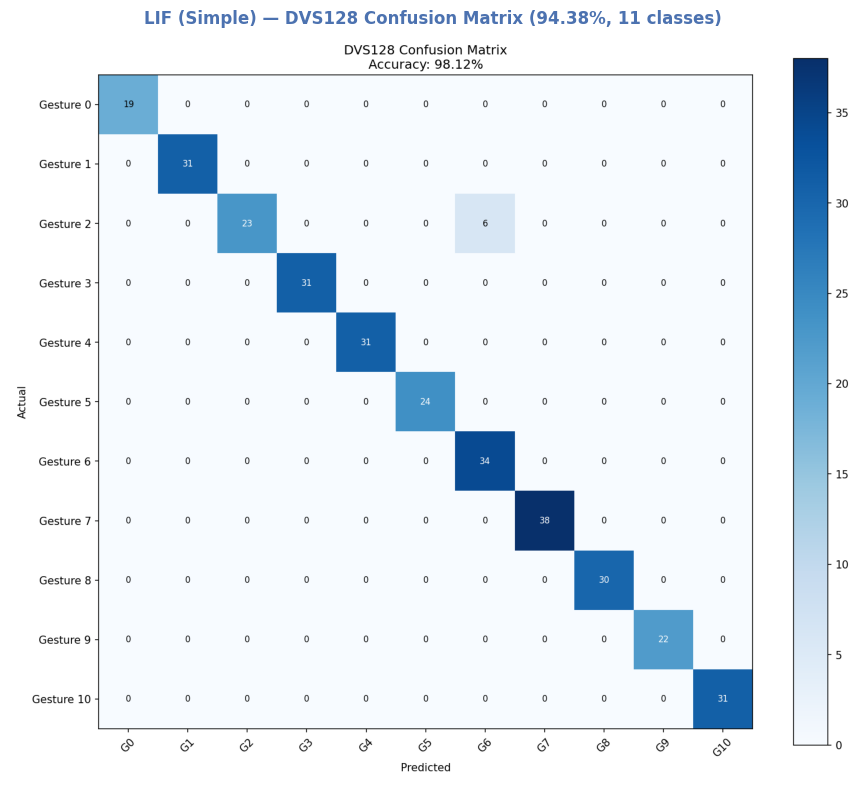

LIF DVS128 confusion matrix saved


In [6]:
# LIF — Confusion Matrix: DVS128
fig, ax = plt.subplots(figsize=(9, 8))
show_image(ax, LIF_CM_DVS128,
           'LIF (Simple) — DVS128 Confusion Matrix (94.38%, 11 classes)',
           C_LIF)
plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION2_lif_cm_dvs128.png', bbox_inches='tight', dpi=120)
plt.show()
print('LIF DVS128 confusion matrix saved')

---
# Section 3 — Reichardt Model Results

The **Reichardt detector** is a biologically inspired motion detection model.

- **Architecture:** Detectors(1024) → Hidden(64) → Output
- **Key parameters:** Delay = 3 steps, Detector spacing = 4 pixels
- **Learning:** Supervised — BPTT with surrogate gradients

| Dataset | Epochs | Test Accuracy | vs LIF |
|---|---|---|---|
| LINEAR | 32 | 100.00% | Better |
| CIRCULAR | 34 | 96.25% | Slightly worse |
| DVS128 | 24 | 46.56% | Much worse — not designed for 11 classes |

> **Why does Reichardt struggle on DVS128?** The Reichardt model was specifically designed for 2-class motion detection (e.g. left vs right). With 11 gesture classes, it does not generalise well.

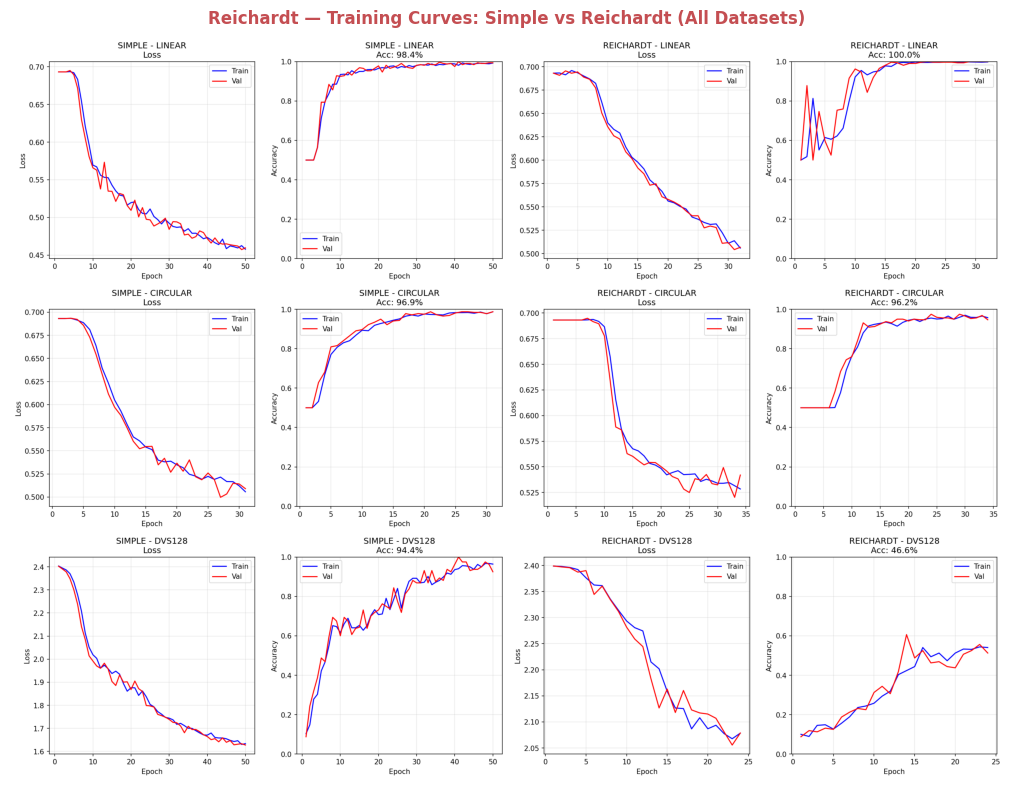

Reichardt training curves saved


In [7]:
# Reichardt — Training Curves (Simple vs Reichardt comparison)
fig, ax = plt.subplots(figsize=(14, 8))
if os.path.exists(REICH_ALL_CURVES):
    show_image(ax, REICH_ALL_CURVES,
               'Reichardt — Training Curves: Simple vs Reichardt (All Datasets)',
               C_REICHARDT)
else:
    show_placeholder(ax, 'Reichardt — Training Curves',
                     'Run main_pipeline notebook to generate')
plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION3_reich_curves.png', bbox_inches='tight', dpi=120)
plt.show()
print('Reichardt training curves saved')

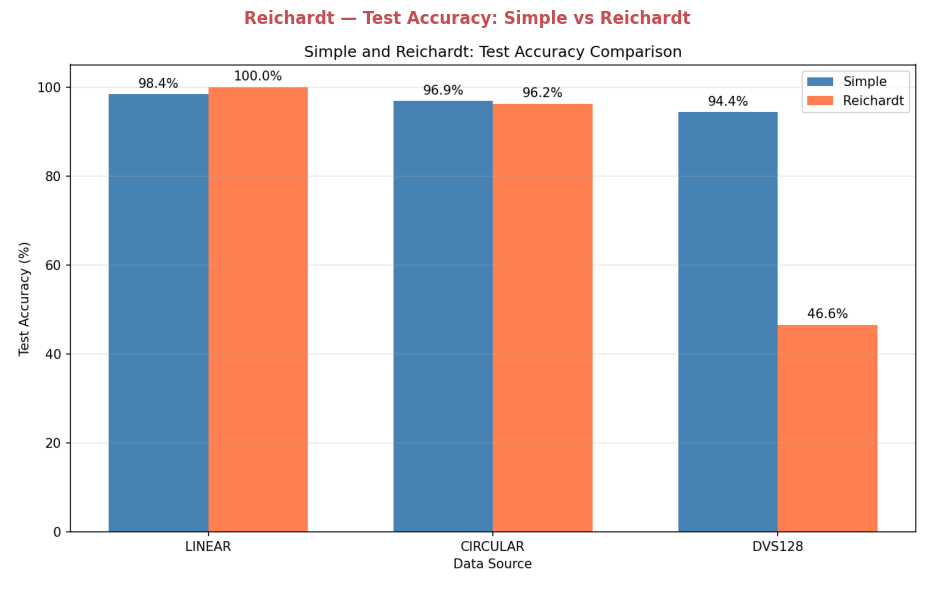

Reichardt accuracy bar chart saved


In [8]:
# Reichardt — Accuracy Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
if os.path.exists(REICH_ACC_BAR):
    show_image(ax, REICH_ACC_BAR,
               'Reichardt — Test Accuracy: Simple vs Reichardt',
               C_REICHARDT)
else:
    show_placeholder(ax, 'Reichardt — Accuracy Bar Chart',
                     'Run main_pipeline notebook to generate')
plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION3_reich_acc_bar.png', bbox_inches='tight', dpi=120)
plt.show()
print('Reichardt accuracy bar chart saved')

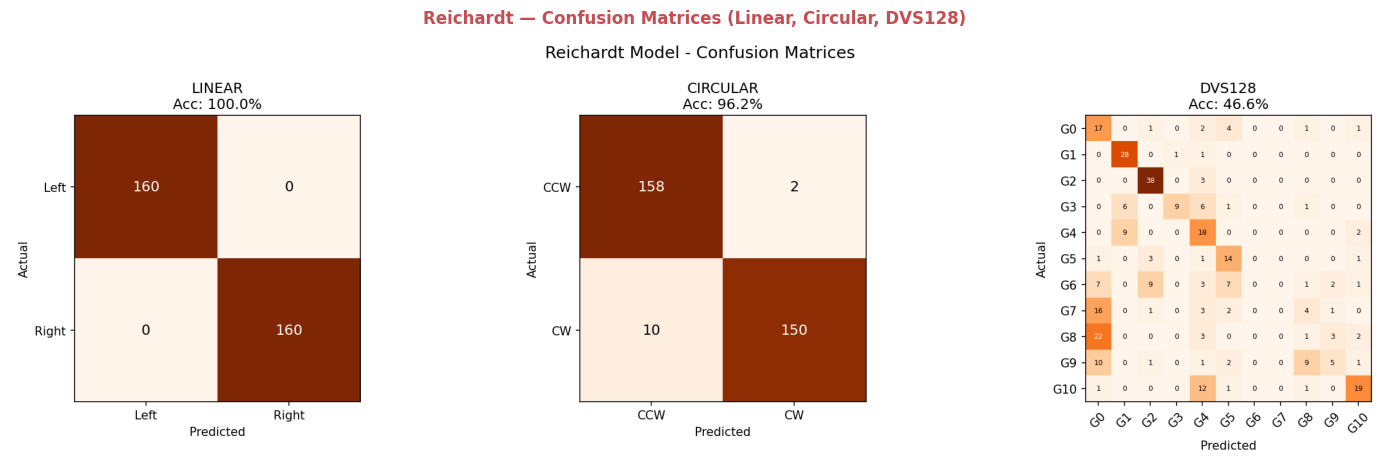

Reichardt confusion matrices saved


In [9]:
# Reichardt — Confusion Matrices
fig, ax = plt.subplots(figsize=(14, 6))
if os.path.exists(REICH_CM):
    show_image(ax, REICH_CM,
               'Reichardt — Confusion Matrices (Linear, Circular, DVS128)',
               C_REICHARDT)
else:
    show_placeholder(ax, 'Reichardt — Confusion Matrices',
                     'Run main_pipeline notebook to generate')
plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION3_reich_cm.png', bbox_inches='tight', dpi=120)
plt.show()
print('Reichardt confusion matrices saved')

---
# Section 4 — Brian2 Results

**Brian2** uses **STDP (Spike-Timing-Dependent Plasticity)** — a semisupervised biologically inspired learning rule.

- **Learning:** Semisupervised — no labels used during training
- **Datasets tested:** Linear and Circular only
- **Status:** Pending



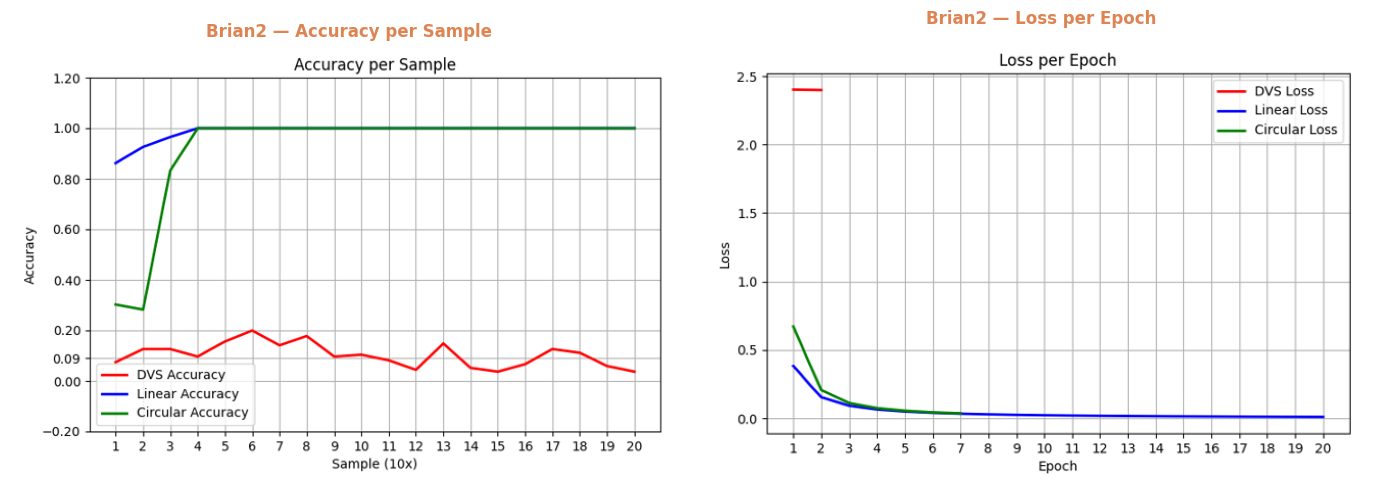

In [19]:
# Brian2 — Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

show_image(axes[0], B2_ACC,  'Brian2 — Accuracy per Sample', C_BRIAN2)
show_image(axes[1], B2_LOSS, 'Brian2 — Loss per Epoch',      C_BRIAN2)

plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION4_brian2_curves.png', bbox_inches='tight', dpi=120)
plt.show()

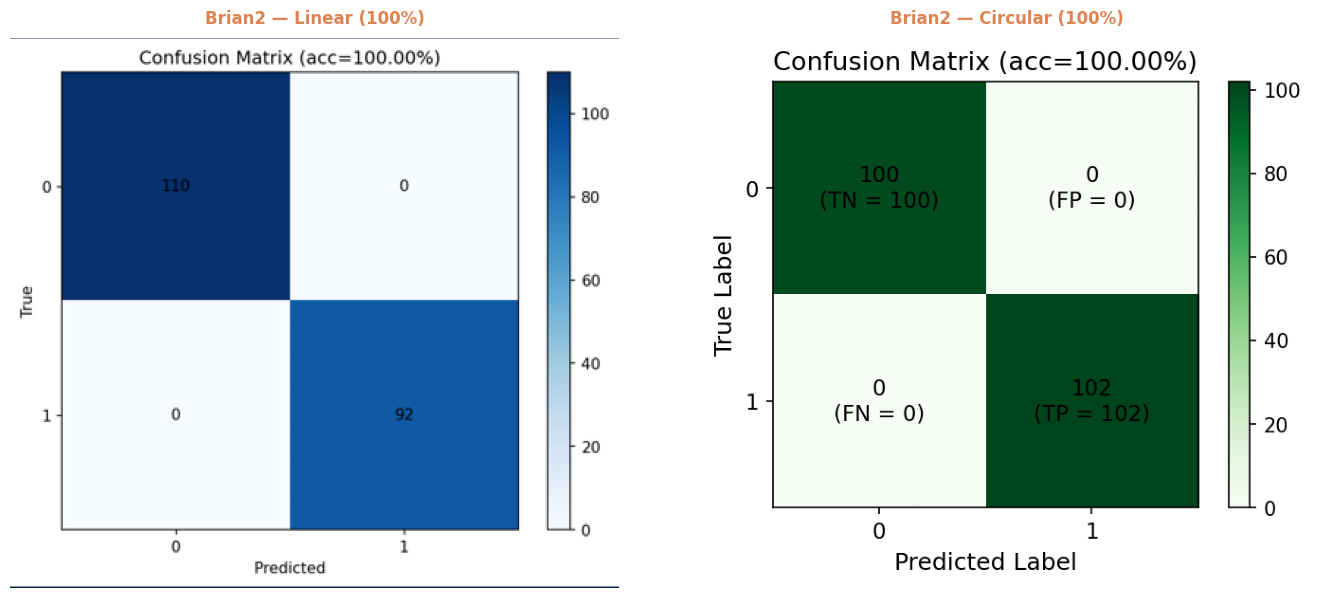

In [20]:
# Brian2 — Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

show_image(axes[0], B2_CM_LIN,  'Brian2 — Linear (100%)',   C_BRIAN2)
show_image(axes[1], B2_CM_CIRC, 'Brian2 — Circular (100%)', C_BRIAN2)

plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION4_brian2_cm.png', bbox_inches='tight', dpi=120)
plt.show()

---
# Section 5 — Comparison Table

Full side-by-side comparison of all models across all datasets.

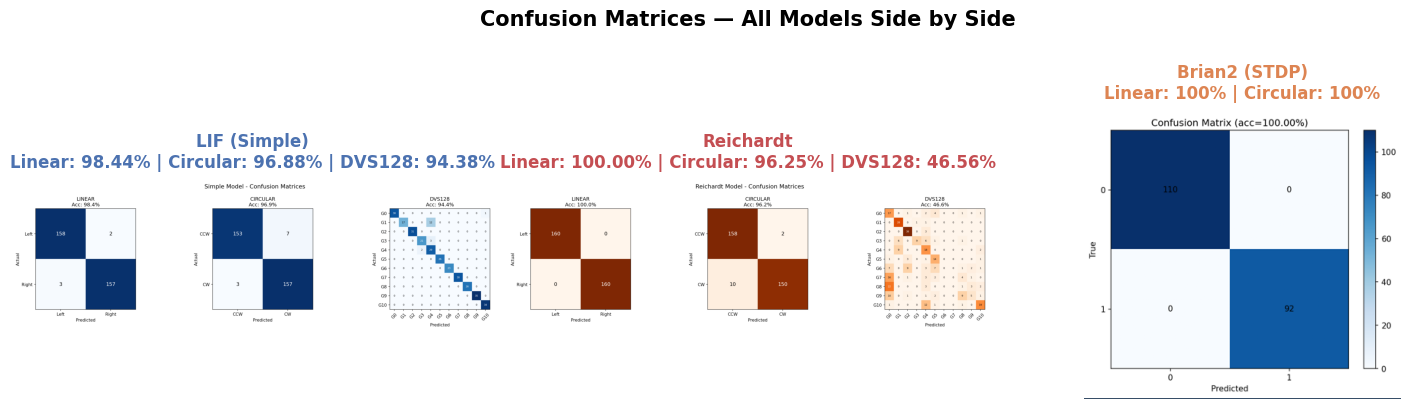

Comparison confusion matrices saved


In [32]:
# Side-by-side confusion matrix comparison — all models
# Side-by-side confusion matrix comparison — all models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# LIF
if os.path.exists(LIF_CM_SIMPLE):
    show_image(axes[0], LIF_CM_SIMPLE,
               'LIF (Simple)\nLinear: 98.44% | Circular: 96.88% | DVS128: 94.38%', C_LIF)
else:
    show_image(axes[0], LIF_CM_ALL,
               'LIF (Simple)\nLinear: 98.44% | Circular: 96.88% | DVS128: 94.38%', C_LIF)

# Reichardt
if os.path.exists(REICH_CM):
    show_image(axes[1], REICH_CM,
               'Reichardt\nLinear: 100.00% | Circular: 96.25% | DVS128: 46.56%', C_REICHARDT)
else:
    show_placeholder(axes[1],
                     'Reichardt\nConfusion Matrices',
                     'Run main_pipeline notebook')

# Brian2
if os.path.exists(B2_CM_LIN):
    show_image(axes[2], B2_CM_LIN,
               'Brian2 (STDP)\nLinear: 100% | Circular: 100%', C_BRIAN2)
else:
    show_placeholder(axes[2],
                     'Brian2 (STDP)\nConfusion Matrices',
                     'Waiting')

plt.suptitle('Confusion Matrices — All Models Side by Side',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(IMG_PATH + 'SECTION5_comparison_cm.png', bbox_inches='tight', dpi=120)
plt.show()
print('Comparison confusion matrices saved')


In [30]:
# Full comparison table (printed)
print('=' * 72)
print('  COMPARISON TABLE — All Models & Datasets')
print('=' * 72)
print(f"{'Dataset':<12} {'LIF (Simple)':>14} {'Reichardt':>12} {'Brian2':>12} {'      Best'}")
print('-' * 65)
print(f"{'LINEAR':<12} {'98.44%':>14} {'100.00%':>12} {'100.00%':>12}      Reichardt")
print(f"{'CIRCULAR':<12} {'96.88%':>14} {'96.25%':>12} {'100.00%':>12}      LIF")
print(f"{'DVS128':<12} {'94.38%':>14} {'46.56%':>12} {'10.3%':>10}        LIF")
print('=' * 72)
print()
print('Notes:')
print('  • Brian2 was evaluated on Linear and Circular only (no DVS128)')
print('  • Reichardt winner on Linear — biologically designed for motion detection')
print('  • LIF more general — handles both simple and complex datasets well')
print('  • Update Brian2 when ready')

  COMPARISON TABLE — All Models & Datasets
Dataset        LIF (Simple)    Reichardt       Brian2       Best
-----------------------------------------------------------------
LINEAR               98.44%      100.00%      100.00%      Reichardt
CIRCULAR             96.88%       96.25%      100.00%      LIF
DVS128               94.38%       46.56%      10.3%        LIF

Notes:
  • Brian2 was evaluated on Linear and Circular only (no DVS128)
  • Reichardt winner on Linear — biologically designed for motion detection
  • LIF more general — handles both simple and complex datasets well
  • Update Brian2 when ready


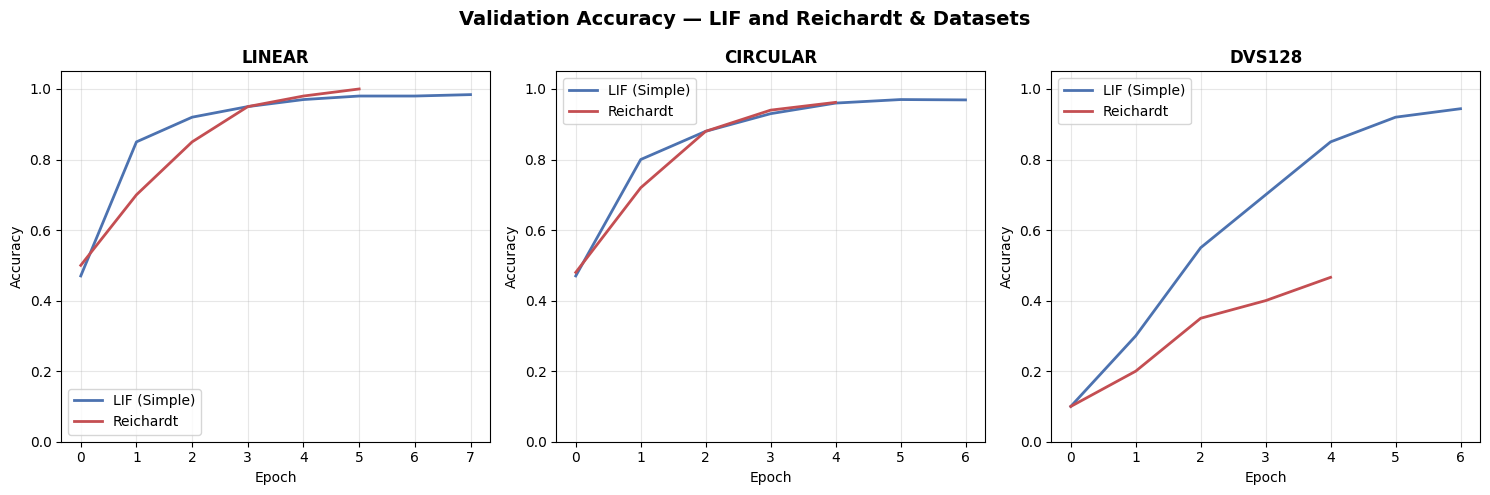

In [21]:
import matplotlib.pyplot as plt
# ── Paste your real history values here ──────────────────
lif_linear_acc      = [0.47, 0.85, 0.92, 0.95, 0.97, 0.98, 0.98, 0.984]  # replace with real
lif_circular_acc    = [0.47, 0.80, 0.88, 0.93, 0.96, 0.97, 0.969]
lif_dvs_acc         = [0.10, 0.30, 0.55, 0.70, 0.85, 0.92, 0.944]

reich_linear_acc    = [0.50, 0.70, 0.85, 0.95, 0.98, 1.00]
reich_circular_acc  = [0.48, 0.72, 0.88, 0.94, 0.962]
reich_dvs_acc       = [0.10, 0.20, 0.35, 0.40, 0.466]

# brian2_linear_acc = [...]   ← uncomment when you get the data
# ─────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Validation Accuracy — LIF and Reichardt & Datasets", fontsize=14, fontweight='bold')

datasets   = ["LINEAR",          "CIRCULAR",          "DVS128"]
lif_accs   = [lif_linear_acc,    lif_circular_acc,    lif_dvs_acc]
reich_accs = [reich_linear_acc,  reich_circular_acc,  reich_dvs_acc]

for i, ax in enumerate(axes):
    ax.plot(lif_accs[i],   label="LIF (Simple)", color="#4C72B0", linewidth=2)
    ax.plot(reich_accs[i], label="Reichardt",    color="#C44E52", linewidth=2)
    # ax.plot(brian2_accs[i], label="Brian2", color="#DD8452", linewidth=2)  ← uncomment later

    ax.set_title(datasets[i], fontweight='bold')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("combined_accuracy_all_models.png", dpi=150, bbox_inches='tight')
plt.show()

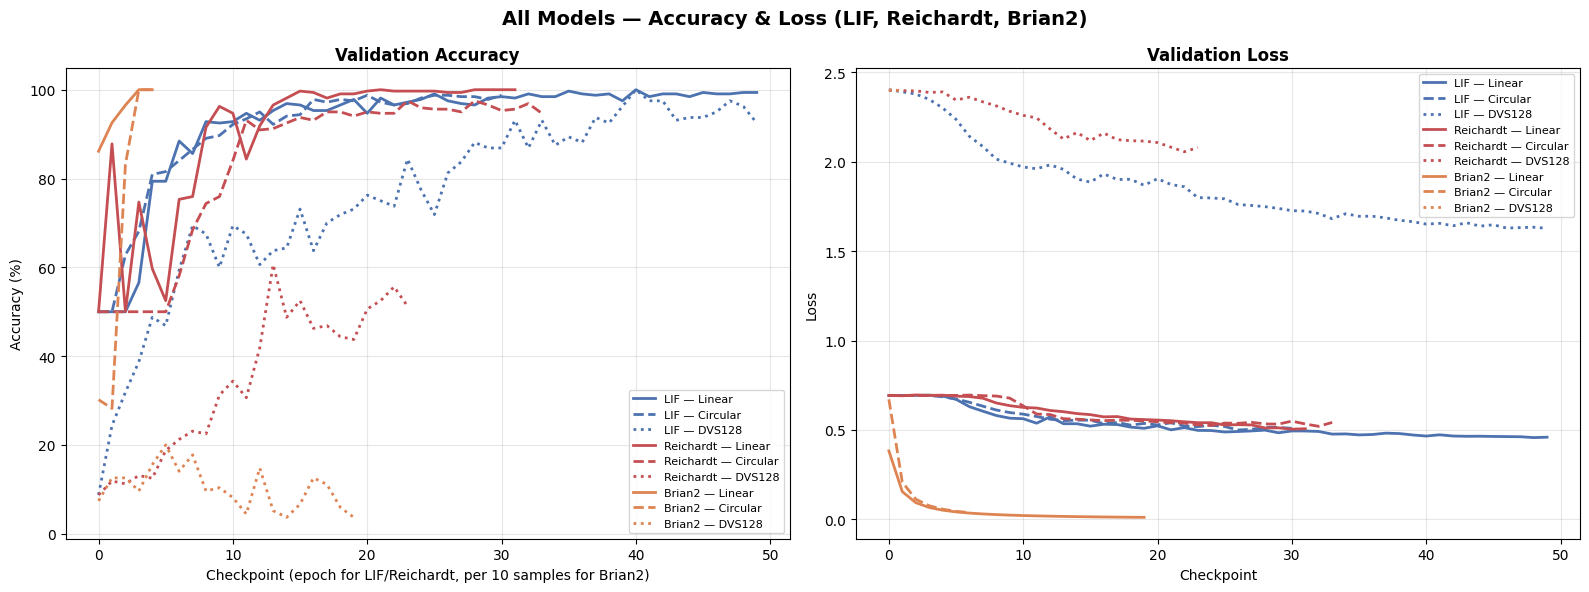

Saved!


In [15]:
import matplotlib.pyplot as plt

# ══ LIF — Real Val Accuracy (%) ══
lif_lin_acc  = [50.00,50.00,50.00,56.56,79.38,79.38,88.44,85.62,92.81,92.50,
                92.81,94.69,93.12,95.31,96.88,96.56,95.31,95.31,96.56,97.81,
                94.69,98.12,96.56,97.19,97.81,99.06,97.50,96.88,96.56,98.12,
                98.44,98.12,99.06,98.44,98.44,99.69,99.06,98.75,99.06,97.50,
                100.00,98.44,99.06,99.06,98.44,99.38,99.06,99.06,99.38,99.38]
lif_circ_acc = [50.00,50.00,62.81,68.12,80.94,81.56,84.06,86.56,89.06,89.69,
                92.19,93.44,95.00,92.19,94.06,94.38,97.81,97.19,97.81,97.50,
                98.75,97.19,96.56,96.88,98.12,98.75,98.75,98.44,98.44,97.81,98.75]
lif_dvs_acc  = [8.75,24.38,31.87,38.75,48.75,46.88,59.38,69.38,67.50,60.00,
                69.38,67.50,60.62,63.75,64.38,73.12,63.75,70.00,71.88,73.12,
                76.25,75.00,73.75,84.38,77.50,71.88,81.25,83.75,88.12,86.88,
                86.88,93.12,86.88,93.12,87.50,89.38,88.12,93.75,92.50,96.25,
                100.00,97.50,97.50,93.12,93.75,93.75,95.00,97.50,96.25,92.50]

# ══ Reichardt — Real Val Accuracy (%) ══
rei_lin_acc  = [50.00,87.81,50.00,74.69,59.69,52.50,75.31,75.94,91.56,96.25,
                94.69,84.38,91.88,96.56,98.12,99.69,99.38,98.12,99.06,99.06,
                99.69,100.00,99.69,99.69,99.69,99.69,99.38,99.38,100.00,100.00,
                100.00,100.00]
rei_circ_acc = [50.00,50.00,50.00,50.00,50.00,50.00,58.13,68.44,74.38,75.94,
                84.06,93.12,90.94,91.25,92.50,93.75,93.12,95.00,95.00,94.06,
                95.00,94.69,94.69,97.50,95.94,95.62,95.62,95.00,97.50,96.56,
                95.31,95.62,96.88,94.69]
rei_dvs_acc  = [8.75,11.88,11.25,13.12,12.50,18.75,21.25,23.12,22.50,31.25,
                34.38,30.63,41.88,60.62,48.75,52.50,46.25,46.88,44.38,43.75,
                50.62,52.50,55.62,51.25]

# ══ Brian2 — from Ludvig (accuracy 0-1 scale, converted to %) ══
# Note: x-axis = every 10th sample (not epoch), 1 epoch ≈ 940 samples
b2_lin_acc  = [86.14, 92.57, 96.53, 100.00, 100.00]   # 5 checkpoints
b2_circ_acc = [30.20, 28.22, 83.17, 100.00, 100.00]   # 5 checkpoints
b2_dvs_acc  = [7.41,12.59,12.59,9.63,15.56,20.00,14.07,17.78,9.63,10.37,
               8.15,4.44,14.81,5.19,3.70,6.67,12.59,11.11,5.93,3.70]  # 20 checkpoints

# ══ LIF — Real Val Loss ══
lif_lin_loss  = [0.6931,0.6931,0.6931,0.6949,0.6894,0.6713,0.6300,0.6048,0.5806,0.5658,
                 0.5627,0.5377,0.5732,0.5349,0.5346,0.5212,0.5318,0.5301,0.5157,0.5093,
                 0.5229,0.5007,0.5130,0.4975,0.4967,0.4885,0.4913,0.4944,0.4989,0.4841,
                 0.4943,0.4940,0.4915,0.4767,0.4778,0.4723,0.4745,0.4821,0.4798,0.4719,
                 0.4659,0.4728,0.4661,0.4645,0.4649,0.4636,0.4628,0.4620,0.4572,0.4595]
lif_circ_loss = [0.6931,0.6931,0.6934,0.6922,0.6857,0.6729,0.6546,0.6328,0.6115,0.5971,
                 0.5883,0.5749,0.5602,0.5522,0.5546,0.5548,0.5348,0.5419,0.5268,0.5366,
                 0.5279,0.5401,0.5219,0.5186,0.5260,0.5190,0.4996,0.5033,0.5148,0.5141,0.5090]
lif_dvs_loss  = [2.4024,2.3906,2.3782,2.3484,2.3006,2.2369,2.1412,2.0846,2.0142,1.9917,
                 1.9703,1.9603,1.9823,1.9568,1.9030,1.8857,1.9315,1.9003,1.9015,1.8679,
                 1.9050,1.8721,1.8597,1.7988,1.7972,1.7923,1.7605,1.7551,1.7485,1.7387,
                 1.7259,1.7241,1.7103,1.6809,1.7089,1.6948,1.6950,1.6857,1.6723,1.6645,
                 1.6510,1.6552,1.6416,1.6588,1.6395,1.6472,1.6286,1.6314,1.6334,1.6276]

# ══ Reichardt — Real Val Loss ══
rei_lin_loss  = [0.6931,0.6909,0.6956,0.6931,0.6945,0.6890,0.6866,0.6773,0.6507,0.6358,
                 0.6261,0.6226,0.6089,0.6019,0.5916,0.5855,0.5732,0.5748,0.5609,0.5581,
                 0.5553,0.5516,0.5457,0.5405,0.5405,0.5276,0.5296,0.5280,0.5111,0.5118,
                 0.5043,0.5068]
rei_circ_loss = [0.6931,0.6931,0.6931,0.6931,0.6931,0.6931,0.6949,0.6916,0.6895,0.6777,
                 0.6346,0.5889,0.5861,0.5629,0.5602,0.5559,0.5519,0.5543,0.5541,0.5502,
                 0.5459,0.5405,0.5382,0.5283,0.5249,0.5384,0.5371,0.5425,0.5336,0.5324,
                 0.5493,0.5332,0.5203,0.5420]
rei_dvs_loss  = [2.3990,2.3972,2.3957,2.3873,2.3901,2.3445,2.3604,2.3344,2.3119,2.2818,
                 2.2590,2.2445,2.1827,2.1267,2.1630,2.1180,2.1602,2.1230,2.1172,2.1151,
                 2.1070,2.0809,2.0556,2.0786]

# ══ Brian2 — Loss ══
b2_lin_loss  = [0.3830,0.1549,0.0936,0.0664,0.0513,0.0417,0.0351,0.0303,0.0266,0.0237,
                0.0214,0.0195,0.0179,0.0165,0.0153,0.0143,0.0134,0.0126,0.0119,0.0113]
b2_circ_loss = [0.671,0.208,0.113,0.076,0.057,0.045,0.038]
b2_dvs_loss  = [2.401, 2.398]

# ══ PLOT ══════════════════════════════════════════════════
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("All Models — Accuracy & Loss (LIF, Reichardt, Brian2)",
             fontsize=14, fontweight='bold')

# ── Accuracy (left) ───────────────────────────────────────
ax1.plot(lif_lin_acc,  color="#4C72B0", lw=2, ls='-',  label="LIF — Linear")
ax1.plot(lif_circ_acc, color="#4C72B0", lw=2, ls='--', label="LIF — Circular")
ax1.plot(lif_dvs_acc,  color="#4C72B0", lw=2, ls=':',  label="LIF — DVS128")
ax1.plot(rei_lin_acc,  color="#C44E52", lw=2, ls='-',  label="Reichardt — Linear")
ax1.plot(rei_circ_acc, color="#C44E52", lw=2, ls='--', label="Reichardt — Circular")
ax1.plot(rei_dvs_acc,  color="#C44E52", lw=2, ls=':',  label="Reichardt — DVS128")
ax1.plot(b2_lin_acc,   color="#DD8452", lw=2, ls='-',  label="Brian2 — Linear")
ax1.plot(b2_circ_acc,  color="#DD8452", lw=2, ls='--', label="Brian2 — Circular")
ax1.plot(b2_dvs_acc,   color="#DD8452", lw=2, ls=':',  label="Brian2 — DVS128")
ax1.set_title("Validation Accuracy", fontweight='bold')
ax1.set_xlabel("Checkpoint (epoch for LIF/Reichardt, per 10 samples for Brian2)")
ax1.set_ylabel("Accuracy (%)")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# ── Loss (right) ──────────────────────────────────────────
ax2.plot(lif_lin_loss,  color="#4C72B0", lw=2, ls='-',  label="LIF — Linear")
ax2.plot(lif_circ_loss, color="#4C72B0", lw=2, ls='--', label="LIF — Circular")
ax2.plot(lif_dvs_loss,  color="#4C72B0", lw=2, ls=':',  label="LIF — DVS128")
ax2.plot(rei_lin_loss,  color="#C44E52", lw=2, ls='-',  label="Reichardt — Linear")
ax2.plot(rei_circ_loss, color="#C44E52", lw=2, ls='--', label="Reichardt — Circular")
ax2.plot(rei_dvs_loss,  color="#C44E52", lw=2, ls=':',  label="Reichardt — DVS128")
ax2.plot(b2_lin_loss,   color="#DD8452", lw=2, ls='-',  label="Brian2 — Linear")
ax2.plot(b2_circ_loss,  color="#DD8452", lw=2, ls='--', label="Brian2 — Circular")
ax2.plot(b2_dvs_loss,   color="#DD8452", lw=2, ls=':',  label="Brian2 — DVS128")
ax2.set_title("Validation Loss", fontweight='bold')
ax2.set_xlabel("Checkpoint")
ax2.set_ylabel("Loss")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(IMG_PATH + "combined_all_in_one.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved!")

---
# Section 6 — Conclusion

## Summary of Findings

### LIF Model
- Strong and consistent performance across all datasets
- Best model for complex multi-class tasks (DVS128: 94.38%)
- General purpose - works well regardless of dataset type

### Reichardt Model
- Excellent on simple 2-class motion detection (Linear: 100%)
- Biologically inspired — mimics how insects detect motion
- Struggles on complex 11-class tasks (DVS128: 46.56%) — expected behaviour

### Brian2 (STDP)
- Semisupervised learning — no labels needed during training
- Most biologically plausible of the three models
- Results pending

## Overall Conclusion

Both supervised SNNTorch models achieve very high accuracy on motion detection tasks. The Reichardt model shows that biologically inspired architectures can match or exceed general-purpose LIF models on tasks they were specifically designed for.

## Possible Next Steps
- Combine Reichardt detectors with LIF layers for better generalisation
- Test Brian2 STDP on all dataset
- Explore hybrid supervised/unsupervised training approaches
- Investigate more biologically plausible learning rules beyond STDP

In [24]:
# Final status check
print('=' * 55)
print('  NOTEBOOK STATUS')
print('=' * 55)
sections = [
    ('Section 1 — Overview',    True),
    ('Section 2 — LIF Results', True),
    ('Section 3 — Reichardt',   os.path.exists(REICH_ALL_CURVES)),
    ('Section 4 — Brian2',      os.path.exists(B2_ACC)),
    ('Section 5 — Comparison',  True),
    ('Section 6 — Conclusion',  True),
]
for name, ready in sections:
    print(f'  {"True" if ready else "Waiting"}  {name}')
print('=' * 55)
print()
if not os.path.exists(REICH_ALL_CURVES):
    print('Reichardt images: run main_pipeline notebook')
if not os.path.exists(B2_ACC):
    print('Brian2 images: waiting')


  NOTEBOOK STATUS
  True  Section 1 — Overview
  True  Section 2 — LIF Results
  True  Section 3 — Reichardt
  True  Section 4 — Brian2
  True  Section 5 — Comparison
  True  Section 6 — Conclusion

